In [1]:
import pandas as pd
import numpy as np
import os

# Load dataset
data_path = "data/diabetes.csv" if os.path.exists("data/diabetes.csv") else "diabetes.csv"
df = pd.read_csv(data_path)
print(df.shape)
print(df.describe())
print(df["Outcome"].value_counts(normalize=True)) 


(768, 9)
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000         

In [2]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols] = df[cols].replace(0, np.nan)
df = df.drop_duplicates()

In [3]:
from sklearn.model_selection import train_test_split

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "SVM": SVC(probability=True, class_weight="balanced"),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

for name, model in models.items():
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model),
    ])
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=["accuracy", "recall", "precision", "roc_auc"])
    results[name] = {k: v.mean() for k, v in scores.items() if k.startswith("test_")}

print(pd.DataFrame(results).T.round(3))

                     test_accuracy  test_recall  test_precision  test_roc_auc
Logistic Regression          0.762        0.701           0.649         0.844
Random Forest                0.772        0.593           0.711         0.823
SVM                          0.761        0.762           0.637         0.837
XGBoost                      0.738        0.593           0.637         0.782


In [5]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(class_weight="balanced", random_state=42)),
])

params = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [4, 6, 8, None],
    "model__min_samples_leaf": [1, 3, 5],
}

grid = GridSearchCV(pipe, params, cv=cv, scoring="recall", n_jobs=-1)
grid.fit(X_train, y_train)
best = grid.best_estimator_

              precision    recall  f1-score   support

           0       0.85      0.73      0.78       100
           1       0.60      0.76      0.67        54

    accuracy                           0.74       154
   macro avg       0.73      0.74      0.73       154
weighted avg       0.76      0.74      0.75       154

ROC-AUC: 0.8140740740740741


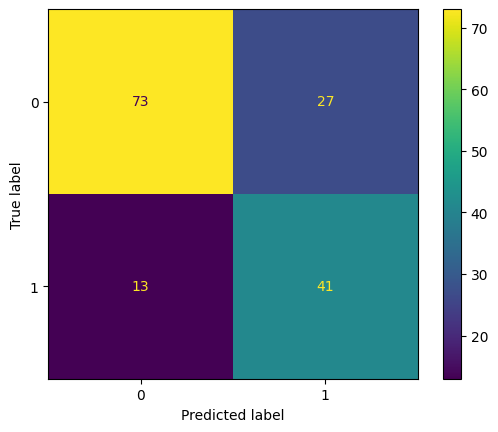

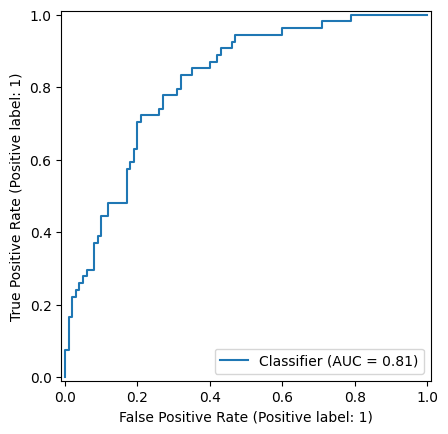

In [6]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt
import os

os.makedirs("images", exist_ok=True)

y_pred = best.predict(X_test)
y_prob = best.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.savefig("images/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# ROC Curve
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.savefig("images/roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()


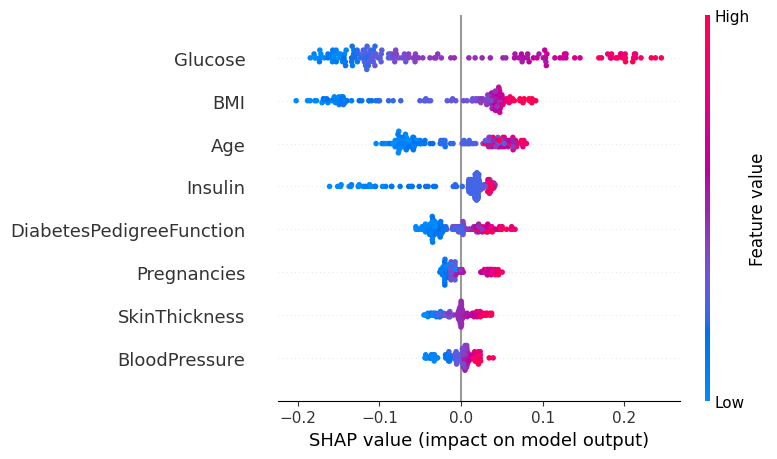

In [7]:
import shap
import matplotlib.pyplot as plt

X_test_t = best[:-1].transform(X_test)  # imputer + scaler
explainer = shap.TreeExplainer(best.named_steps["model"])
shap_values = explainer.shap_values(X_test_t)

plt.figure()
if isinstance(shap_values, list):
    shap.summary_plot(shap_values[1], X_test_t, feature_names=X.columns, show=False)
elif len(shap_values.shape) == 3:
    shap.summary_plot(shap_values[:, :, 1], X_test_t, feature_names=X.columns, show=False)
else:
    shap.summary_plot(shap_values, X_test_t, feature_names=X.columns, show=False)

plt.savefig("images/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()


In [8]:
# import joblib
# joblib.dump(best, "diabetes_model.pkl")